# 08 · ¿Cada segmento gana o pierde plata?

**Preguntas de decisión**

1. **¿La mora total cambió por la mezcla o por la tasa?** Cuando sube el EVER de la cartera, la acción depende de si se originó más de un segmento riesgoso (mezcla: se gestiona con apetito y cuotas) o si un segmento empeoró por dentro (tasa: se gestiona con la regla de ese segmento).
2. **¿Qué segmentos crean o destruyen valor después de la pérdida esperada?** Una tasa de mora no basta para decidir. Un segmento con 12 % de EVER puede ser rentable si su margen lo soporta, y uno con 6 % puede no serlo.
3. **¿Cuánto vale endurecer el corte de score en cada estrategia?** Es el cambio de política más directo, y se puede evaluar con la población aprobada.

**Impacto esperado:** pasar de "este segmento tiene X % de mora" a "este segmento crea o destruye COP Y al año, y este corte vale COP Z".

> **Estado:** plantilla con demostración aislada simulada. Los parámetros económicos de la demostración son **supuestos ilustrativos**, no tarifas ni costos de una entidad.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'decision_core.py').exists():
    root = next(p for p in [BASE, *BASE.parents] if (p / '03-financial-risk').is_dir())
    BASE = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(BASE))
import decision_core as dc
from vintage_core import build_vintage, summarize_vintage
from demo_inputs import demo_cartera
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
AZUL, OCRE, GRIS, ROJO = '#25658c', '#d4854a', '#9aa5b1', '#b5443b'
SIM = 'Datos simulados · no representa una cartera'
pd.options.display.float_format = '{:,.4f}'.format

def leer(nombre):
    """Lee una plantilla local; las del repositorio solo tienen encabezados."""
    return pd.read_csv(BASE / nombre, encoding='utf-8-sig')

def pct(x, d=1):
    return 'n/d' if pd.isna(x) else f'{100 * x:.{d}f} %'

def cop(x):
    return 'n/d' if pd.isna(x) else f'COP {x / 1e6:,.1f} M'

## 1 · Mezcla frente a tasa

Con pesos $w_s$ (participación en la originación) y tasas $r_s$ por segmento, la tasa total es $R=\sum_s w_s r_s$. La descomposición simétrica es exacta:

$$\Delta R=\underbrace{\sum_s (w_{1s}-w_{0s})\tfrac{r_{0s}+r_{1s}}{2}}_{\text{mezcla}}+\underbrace{\sum_s (r_{1s}-r_{0s})\tfrac{w_{0s}+w_{1s}}{2}}_{\text{tasa}}.$$

El resultado depende de la segmentación elegida: un efecto "tasa" puede ser mezcla en una dimensión que no se incluyó. Por eso se reporta con dos o tres segmentaciones alternativas.

### Con datos de la entidad

In [2]:
panel = leer('plantilla_panel_mensual.csv'); origen = leer('plantilla_creditos_originacion.csv')
economia = leer('plantilla_economia_segmento.csv')
print(f'Panel: {len(panel):,} | originación: {len(origen):,} | economía por segmento: {len(economia):,}')
if panel.empty or origen.empty:
    print('PENDIENTE: panel y originación para la descomposición; definir períodos a comparar y segmentaciones.')
if economia.empty:
    print('PENDIENTE: ingresos, costos, LGD y capital por segmento aprobados por Finanzas; la PD sale del notebook 07.')

Panel: 0 | originación: 0 | economía por segmento: 0
PENDIENTE: panel y originación para la descomposición; definir períodos a comparar y segmentaciones.
PENDIENTE: ingresos, costos, LGD y capital por segmento aprobados por Finanzas; la PD sale del notebook 07.


### Demostración aislada

In [3]:
# Cartera ficticia con mecanismos plantados (ver demo_inputs.demo_cartera).
DEMO = demo_cartera()
V = DEMO['verdad']
cuentas, solicitudes, panel_demo, macro_demo = DEMO['cuentas'], DEMO['solicitudes'], DEMO['panel'], DEMO['macro']
cuentas['banda_score'] = pd.cut(cuentas.score_buro, [0, 620, 660, 700, 2000], right=False,
                                labels=['<620', '620–659', '660–699', '700+'])
print(f'Solicitudes simuladas: {len(solicitudes):,} | aprobadas: {len(cuentas):,} | '
      f'EVER30@MOB3 simulado: {pct(cuentas.evento_temprano.mean())}')

Solicitudes simuladas: 30,000 | aprobadas: 20,379 | EVER30@MOB3 simulado: 10.5 %


In [4]:
cuentas['segmento'] = cuentas.estrategia_originacion + ' | ' + cuentas.banda_score.astype(str)
cuentas['semestre'] = np.where(cuentas.corte_origen < '2024-07', 'S1-2024', 'S2-2024')

def por_segmento(df, col):
    return df.groupby(col, observed=True).agg(n=('evento_temprano', 'size'), eventos=('evento_temprano', 'sum')).reset_index()

resultados = {}
for col in ['segmento', 'tipo_persona', 'departamento']:
    s0, s1 = (por_segmento(cuentas[cuentas.semestre == s], col) for s in ('S1-2024', 'S2-2024'))
    resultados[col] = dc.shift_share(s0, s1, segment_col=col)
resumen = pd.DataFrame({k: v.attrs for k, v in resultados.items()}).T
resumen['cambio_total'] = resumen.tasa_comparacion - resumen.tasa_base
display(resumen[['tasa_base', 'tasa_comparacion', 'cambio_total', 'efecto_mezcla', 'efecto_tasa']])
for k, v in resultados.items():
    assert abs(v.attrs['efecto_mezcla'] + v.attrs['efecto_tasa'] - (v.attrs['tasa_comparacion'] - v.attrs['tasa_base'])) < 1e-12
display(resultados['segmento'].sort_values('efecto_tasa', ascending=False).head(4))

,tasa_base,tasa_comparacion,cambio_total,efecto_mezcla,efecto_tasa
segmento,0.1037,0.1066,0.0030,-0.0005,0.0035
tipo_persona,0.1037,0.1066,0.0030,-0.0000,0.0030
departamento,0.1037,0.1066,0.0030,0.0004,0.0026


,segmento,peso_base,peso_comparacion,tasa_base,tasa_comparacion,efecto_mezcla,efecto_tasa
1,Experian | 660–699,0.1914,0.1993,0.0796,0.0974,0.0007,0.0035
0,Experian | 620–659,0.2173,0.2110,0.1280,0.1417,-0.0008,0.0029
2,Experian | 700+,0.1892,0.1843,0.0618,0.0734,-0.0003,0.0022
7,TPV | <620,0.1314,0.1285,0.1114,0.1152,-0.0003,0.0005


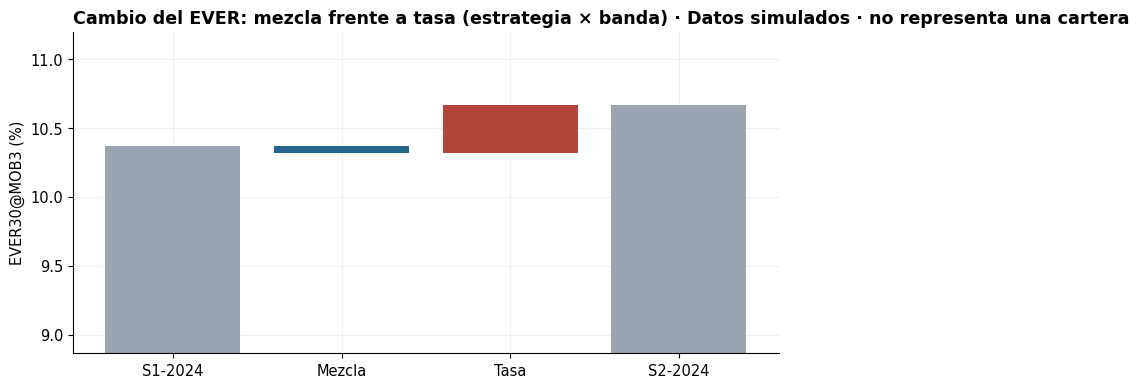

**Lectura (simulada).** El EVER pasa de 10.4 % a 10.7 %. La mezcla aporta -0.05 pp y la tasa dentro de los segmentos +0.35 pp. El segmento con mayor deterioro propio es **Experian | 660–699** (+0.35 pp). Si la tasa domina, la conversación es sobre la regla del segmento o sobre el entorno (notebook 07), no sobre el apetito por volumen.

In [5]:
r = resultados['segmento'].attrs
pasos = [('S1-2024', r['tasa_base']), ('Mezcla', r['efecto_mezcla']), ('Tasa', r['efecto_tasa']), ('S2-2024', r['tasa_comparacion'])]
fig, ax = plt.subplots(figsize=(8, 4))
acumulado = r['tasa_base']
ax.bar(0, 100 * r['tasa_base'], color=GRIS)
for i, (nombre, val) in enumerate(pasos[1:3], start=1):
    ax.bar(i, 100 * val, bottom=100 * acumulado, color=ROJO if val > 0 else AZUL)
    acumulado += val
ax.bar(3, 100 * r['tasa_comparacion'], color=GRIS)
ax.set_xticks(range(4), [p[0] for p in pasos]); ax.set_ylim(100 * min(r['tasa_base'], r['tasa_comparacion']) - 1.5, None)
ax.set(ylabel='EVER30@MOB3 (%)', title=f'Cambio del EVER: mezcla frente a tasa (estrategia × banda) · {SIM}')
plt.tight_layout(); plt.show()
top = resultados['segmento'].sort_values('efecto_tasa', ascending=False).iloc[0]
display(Markdown(f"**Lectura (simulada).** El EVER pasa de {pct(r['tasa_base'])} a {pct(r['tasa_comparacion'])}. "
                 f"La mezcla aporta {100 * r['efecto_mezcla']:+.2f} pp y la tasa dentro de los segmentos {100 * r['efecto_tasa']:+.2f} pp. "
                 f"El segmento con mayor deterioro propio es **{top.segmento}** ({100 * top.efecto_tasa:+.2f} pp). "
                 "Si la tasa domina, la conversación es sobre la regla del segmento o sobre el entorno (notebook 07), no sobre el apetito por volumen."))

## 2 · Economía por segmento y PD de equilibrio

Por cuenta y año, con horizonte de vida $H$:

$$\text{margen ajustado}=\underbrace{B\,i+\text{intercambio}+\text{comisiones}}_{\text{ingreso}}-\underbrace{B\,f+\text{operación}+\tfrac{\text{adquisición}}{H}}_{\text{costo}}-\underbrace{PD\cdot LGD\cdot EAD}_{\text{pérdida esperada}}.$$

La **PD de equilibrio** es la PD anual que lleva el margen a cero: $PD^{*}=(\text{ingreso}-\text{costo})/(LGD\cdot EAD)$. La **holgura** $PD^{*}-PD$ indica cuánto riesgo adicional tolera el segmento antes de destruir valor. Con capital económico $K=\kappa B$, $\text{RAROC}=\text{margen}/K$, y el valor sobre el costo de capital es $\text{margen}-h\,K$.

La PD anual sale del puente del notebook 07: $\widehat L_{18}=r\,a+(1-r)\,b$ y $PD=1-(1-\widehat L_{18})^{12/18}$.

In [6]:
# SUPUESTOS ILUSTRATIVOS: reemplazar por cifras aprobadas por Finanzas (plantilla_economia_segmento.csv).
SUPUESTOS = dict(tasa_interes_anual=.27, ingreso_intercambio_anual_cop=40_000, comision_por_cuenta_con_avance=60_000,
                 costo_fondeo_anual=.105, costo_operativo_anual_cop=110_000, costo_adquisicion_cop=180_000,
                 horizonte_anios=3, capital_ratio=.12, hurdle=.15,
                 anios_margen_hasta_castigo=.75, costo_cobranza_por_malo=100_000)
display(pd.Series(SUPUESTOS, name='supuesto ilustrativo').to_frame())

puente = dc.bridge_to_loss(cuentas).iloc[0]
cast = cuentas[(cuentas.seguimiento_largo_completo == 1) & (cuentas.castigo_largo == 1)]
LGD = cast.perdida_neta_cop.sum() / cast.saldo_mob3.sum()
seg = cuentas.groupby('segmento').agg(n_cuentas=('evento_temprano', 'size'), tasa_temprana=('evento_temprano', 'mean'),
                                      saldo_promedio_cop=('saldo_mob3', 'mean'),
                                      share_avance=('primer_mob_avance', lambda s: s.notna().mean())).reset_index()
seg['pd_18m'] = dc.implied_loss_rate(seg.tasa_temprana, puente.p_castigo_dado_evento, puente.p_castigo_sin_evento)
seg['pd_anual'] = 1 - (1 - seg.pd_18m) ** (12 / 18)
seg['lgd'] = LGD
for k in ['tasa_interes_anual', 'ingreso_intercambio_anual_cop', 'costo_fondeo_anual', 'costo_operativo_anual_cop', 'costo_adquisicion_cop']:
    seg[k] = SUPUESTOS[k]
seg['ingreso_comisiones_anual_cop'] = seg.share_avance * SUPUESTOS['comision_por_cuenta_con_avance']
eco = dc.segment_economics(seg, horizonte_anios=SUPUESTOS['horizonte_anios'], capital_ratio=SUPUESTOS['capital_ratio'],
                           hurdle=SUPUESTOS['hurdle'])
assert np.allclose(eco.margen_ajustado_cuenta, eco.ingreso_cuenta - eco.costo_cuenta - eco.perdida_esperada_cuenta)
cols = ['segmento', 'n_cuentas', 'tasa_temprana', 'pd_anual', 'pd_equilibrio', 'holgura_pd', 'margen_ajustado_cuenta', 'raroc', 'valor_sobre_hurdle_total']
display(eco[cols].sort_values('holgura_pd'))

,supuesto ilustrativo
tasa_interes_anual,0.2700
ingreso_intercambio_anual_cop,"40,000.0000"
comision_por_cuenta_con_avance,"60,000.0000"
costo_fondeo_anual,0.1050
costo_operativo_anual_cop,"110,000.0000"
costo_adquisicion_cop,"180,000.0000"
horizonte_anios,3.0000
capital_ratio,0.1200
hurdle,0.1500
anios_margen_hasta_castigo,0.7500


,segmento,n_cuentas,tasa_temprana,pd_anual,pd_equilibrio,holgura_pd,margen_ajustado_cuenta,raroc,valor_sobre_hurdle_total
7,TPV | <620,2648,0.1133,0.0399,0.0620,0.0221,"18,567.6840",0.1560,"1,879,823.3221"
5,TPV | 660–699,1177,0.0578,0.0265,0.0540,0.0275,"22,713.2445",0.1940,"6,063,782.7191"
4,TPV | 620–659,1773,0.0835,0.0327,0.0606,0.0278,"23,555.2104",0.1966,"9,905,943.9739"
3,Experian | <620,1914,0.1970,0.0603,0.0892,0.0290,"24,549.9145",0.2047,"12,550,360.2824"
0,Experian | 620–659,4364,0.1347,0.0451,0.0811,0.0360,"30,522.5753",0.2540,"54,544,748.8135"
1,Experian | 660–699,3981,0.0887,0.0340,0.0731,0.0392,"33,141.6356",0.2765,"60,373,261.1788"
6,TPV | 700+,717,0.0725,0.0301,0.1251,0.0950,"161,364.0002",0.6709,"89,829,504.1227"
2,Experian | 700+,3805,0.0675,0.0289,0.1297,0.1009,"171,556.4649",0.7122,"515,283,434.8775"


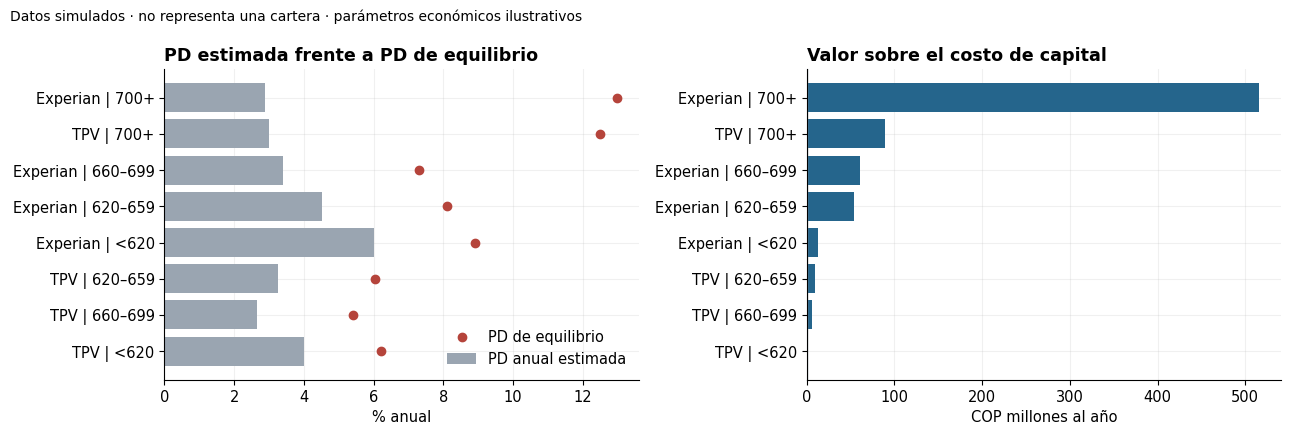

**Lectura (simulada).** Todos los segmentos tienen margen positivo después de la pérdida esperada y cubren el costo de capital (15 %); el RAROC va de 16 % a 71 %. El de menor holgura es **TPV | <620**: PD anual 4.0 % frente a 6.2 % de equilibrio, es decir, tolera 2.2 pp más de PD antes de perder dinero. La palanca natural es precio o cupo antes que cierre: con estos supuestos, cada punto de tasa vale COP 248.8 M al año en la cartera simulada.

In [7]:
e = eco.sort_values('holgura_pd')
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].barh(e.segmento, 100 * e.pd_anual, color=GRIS, label='PD anual estimada')
axs[0].scatter(100 * e.pd_equilibrio, e.segmento, color=ROJO, zorder=3, label='PD de equilibrio')
axs[0].set(xlabel='% anual', title='PD estimada frente a PD de equilibrio'); axs[0].legend(frameon=False, loc='lower right')
axs[1].barh(e.segmento, e.valor_sobre_hurdle_total / 1e6, color=np.where(e.valor_sobre_hurdle_total < 0, ROJO, AZUL))
axs[1].axvline(0, color=GRIS, lw=1); axs[1].set(xlabel='COP millones al año', title='Valor sobre el costo de capital')
fig.suptitle(SIM + ' · parámetros económicos ilustrativos', x=.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()
destruye = eco[eco.valor_sobre_hurdle_total < 0]
sin_margen = eco[eco.pd_anual > eco.pd_equilibrio]
peor = e.iloc[0]
if len(sin_margen):
    diag = (f"{len(sin_margen)} segmento(s) tienen PD anual por encima de la de equilibrio y destruyen valor aun sin cargar capital.")
elif len(destruye):
    diag = (f"Todos los segmentos tienen margen positivo después de la pérdida esperada, pero {len(destruye)} no cubre el costo "
            f"de capital ({pct(SUPUESTOS['hurdle'], 0)}): en conjunto restan {cop(-destruye.valor_sobre_hurdle_total.sum())} al año.")
else:
    diag = (f"Todos los segmentos tienen margen positivo después de la pérdida esperada y cubren el costo de capital "
            f"({pct(SUPUESTOS['hurdle'], 0)}); el RAROC va de {pct(eco.raroc.min(), 0)} a {pct(eco.raroc.max(), 0)}.")
display(Markdown(f"**Lectura (simulada).** {diag} El de menor holgura es **{peor.segmento}**: PD anual {pct(peor.pd_anual)} frente a "
                 f"{pct(peor.pd_equilibrio)} de equilibrio, es decir, tolera {100 * peor.holgura_pd:.1f} pp más de PD antes de perder dinero. "
                 "La palanca natural es precio o cupo antes que cierre: con estos supuestos, cada punto de tasa vale "
                 f"{cop((eco.saldo_promedio_cop * eco.n_cuentas).sum() * .01)} al año en la cartera simulada."))

## 3 · Valor de endurecer el corte de score

Para cada cuenta aprobada se estima su valor de vida con margen anual $m_i$ = ingreso − costo. Un bueno vale $v_i=H m_i-b\,LGD\,B_i$. Un malo (EVER30@MOB3) se cura con probabilidad $1-a$ y conserva $H m_i$; con probabilidad $a$ se castiga, genera margen solo hasta el castigo ($\tau$ años) y pierde $LGD\,B_i$; siempre paga cobranza $k$: $v_i=(1-a)H m_i+a(\tau m_i-LGD\,B_i)-k$. Con $\bar g$ el valor medio de un bueno y $\bar\ell$ la pérdida media de un malo, conviene cortar una banda solo si su tasa de malos supera $\bar g/(\bar g+\bar\ell)$, la **tasa de malos de equilibrio**. Subir el corte a $c$ deja de aprobar las cuentas con score $<c$ y cambia el valor en $-\sum_{i:\,s_i<c} v_i$.

**Límite fundamental:** con la población aprobada solo se puede evaluar **endurecer**. Aflojar el corte exige saber cómo se habrían comportado los rechazados (notebook 09).

,estrategia,escenario,corte_actual,corte_optimo,aprobacion_retenida,valor_neto_cop,tasa_malos_equilibrio,tasa_malos_banda_marginal
0,Experian,base,600,600,1.0000,0.0000,0.5452,0.1970
1,Experian,margen −30 %,600,600,1.0000,0.0000,0.3964,0.1970
2,Experian,LGD +10 pp,600,600,1.0000,0.0000,0.5046,0.1970
3,Experian,margen −30 % y LGD +10 pp,600,600,1.0000,0.0000,0.3638,0.1970
4,TPV,base,560,560,1.0000,0.0000,0.3891,0.1274
5,TPV,margen −30 %,560,560,1.0000,0.0000,0.2728,0.1274
6,TPV,LGD +10 pp,560,560,1.0000,0.0000,0.3571,0.1274
7,TPV,margen −30 % y LGD +10 pp,560,560,1.0000,0.0000,0.2482,0.1274


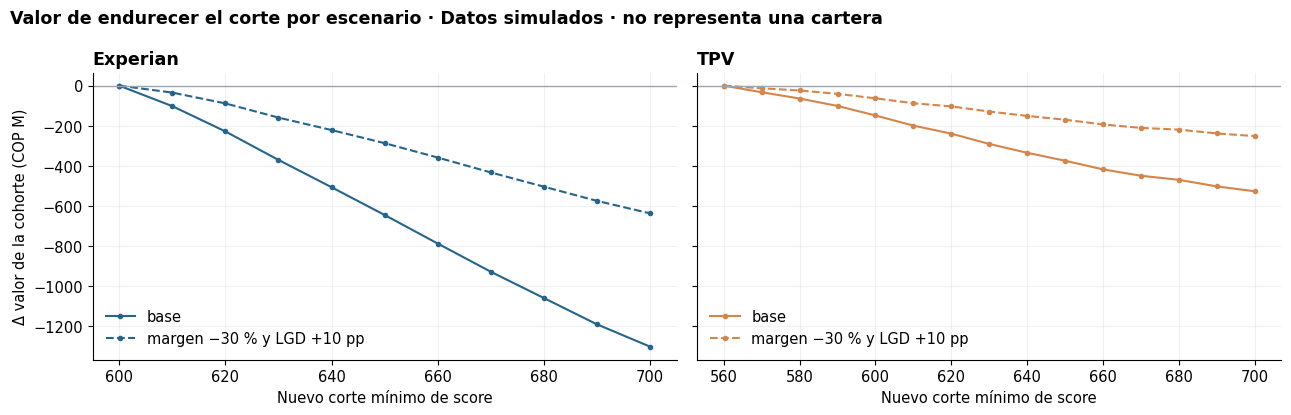

**Lectura (simulada).** En **Experian** la banda marginal tiene 19.7 % de malos frente a un equilibrio de 54.5 %: el corte actual es eficiente; en el escenario estresado el equilibrio baja a 36.4 % y el corte sigue siendo eficiente. En **TPV** la banda marginal tiene 12.7 % de malos frente a un equilibrio de 38.9 %: el corte actual es eficiente; en el escenario estresado el equilibrio baja a 24.8 % y el corte sigue siendo eficiente. En Experian y TPV la banda marginal tiene menos de la mitad de la mora que el margen tolera: la señal es que el corte puede ser **demasiado conservador** y hay valor en aflojarlo. Ese valor no se puede medir con aprobados: requiere el desempeño inferido de los rechazados (notebook 09) y una prueba controlada (notebook 11). La tasa de malos de equilibrio es la cifra que se debe vigilar: si la mora de la banda marginal la supera, el corte quedó viejo.

In [8]:
a_, b_ = puente.p_castigo_dado_evento, puente.p_castigo_sin_evento
H = SUPUESTOS['horizonte_anios']
ingreso = (cuentas.saldo_mob3 * SUPUESTOS['tasa_interes_anual'] + SUPUESTOS['ingreso_intercambio_anual_cop']
           + cuentas.primer_mob_avance.notna() * SUPUESTOS['comision_por_cuenta_con_avance'])
costo = (cuentas.saldo_mob3 * SUPUESTOS['costo_fondeo_anual'] + SUPUESTOS['costo_operativo_anual_cop']
         + SUPUESTOS['costo_adquisicion_cop'] / H)

def valor_vida(df, margen=1.0, lgd=LGD):
    return dc.account_lifetime_value(df, bad_col='evento_temprano', balance_col='saldo_mob3',
                                     annual_margin=(ingreso[df.index] - costo[df.index]) * margen, horizon_years=H,
                                     p_loss_bad=a_, p_loss_good=b_, lgd=lgd,
                                     years_to_loss=SUPUESTOS['anios_margen_hasta_castigo'],
                                     collection_cost_bad=SUPUESTOS['costo_cobranza_por_malo'])

ESCENARIOS = {'base': (1.0, LGD), 'margen −30 %': (.7, LGD), 'LGD +10 pp': (1.0, min(LGD + .10, 1)),
              'margen −30 % y LGD +10 pp': (.7, min(LGD + .10, 1))}
filas, curvas = [], {}
for est in ['Experian', 'TPV']:
    g = cuentas[cuentas.estrategia_originacion == est].copy()
    cortes = np.arange(g.score_buro.min() // 10 * 10, 701, 10)
    for nombre, (m, lgd) in ESCENARIOS.items():
        v = valor_vida(g, m, lgd)
        g['ganancia_bueno'] = v.where(g.evento_temprano == 0, 0)
        g['perdida_malo'] = (-v).where(g.evento_temprano == 1, 0)
        t = dc.cutoff_tightening(g, score_col='score_buro', bad_col='evento_temprano', gain_good='ganancia_bueno',
                                 loss_bad='perdida_malo', cutoffs=cortes)
        assert abs(t.valor_neto.iloc[0]) < 1e-6, 'El corte actual no debe cambiar el valor'
        curvas[(est, nombre)] = t
        mejor = t.loc[t.valor_neto.idxmax()]
        filas.append({'estrategia': est, 'escenario': nombre, 'corte_actual': int(g.score_buro.min()), 'corte_optimo': int(mejor.corte),
                      'aprobacion_retenida': mejor.aprobacion_retenida, 'valor_neto_cop': mejor.valor_neto,
                      'tasa_malos_equilibrio': dc.breakeven_bad_rate(v, g.evento_temprano),
                      'tasa_malos_banda_marginal': g.loc[g.score_buro < g.score_buro.min() + 20, 'evento_temprano'].mean()})
rec = pd.DataFrame(filas); display(rec)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, est in zip(axs, ['Experian', 'TPV']):
    for (nombre, estilo) in [('base', '-'), ('margen −30 % y LGD +10 pp', '--')]:
        t = curvas[(est, nombre)]
        ax.plot(t.corte, t.valor_neto / 1e6, estilo, marker='.', color=AZUL if est == 'Experian' else OCRE, label=nombre)
    ax.axhline(0, color=GRIS, lw=1); ax.set(title=est, xlabel='Nuevo corte mínimo de score'); ax.legend(frameon=False)
axs[0].set_ylabel('Δ valor de la cohorte (COP M)')
fig.suptitle(f'Valor de endurecer el corte por escenario · {SIM}', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

base = rec[rec.escenario == 'base'].set_index('estrategia'); estres = rec[rec.escenario == 'margen −30 % y LGD +10 pp'].set_index('estrategia')
frases = []
for est in base.index:
    b, s_ = base.loc[est], estres.loc[est]
    frases.append(f"En **{est}** la banda marginal tiene {pct(b.tasa_malos_banda_marginal)} de malos frente a un equilibrio de "
                  f"{pct(b.tasa_malos_equilibrio)}: " + ("el corte actual es eficiente" if b.corte_optimo == b.corte_actual
                  else f"conviene subir a {b.corte_optimo} ({cop(b.valor_neto_cop)})") +
                  f"; en el escenario estresado el equilibrio baja a {pct(s_.tasa_malos_equilibrio)}" +
                  (f" y el corte óptimo pasa a {s_.corte_optimo} ({cop(s_.valor_neto_cop)})." if s_.corte_optimo > s_.corte_actual else " y el corte sigue siendo eficiente."))
holgado = [est for est in base.index if base.loc[est, 'tasa_malos_banda_marginal'] < .5 * base.loc[est, 'tasa_malos_equilibrio']]
cierre = (f" En {' y '.join(holgado)} la banda marginal tiene menos de la mitad de la mora que el margen tolera: la señal es que el corte "
          "puede ser **demasiado conservador** y hay valor en aflojarlo. Ese valor no se puede medir con aprobados: requiere el "
          "desempeño inferido de los rechazados (notebook 09) y una prueba controlada (notebook 11).") if holgado else ''
display(Markdown('**Lectura (simulada).** ' + ' '.join(frases) + cierre + ' La tasa de malos de equilibrio es la cifra que se debe '
                 'vigilar: si la mora de la banda marginal la supera, el corte quedó viejo.'))

## Decisiones y límites

- **Mezcla frente a tasa** separa una decisión de apetito (cuánto originar de cada segmento) de una de regla (cómo aprobar dentro del segmento).
- **La PD de equilibrio** convierte la discusión de riesgo en una de precio y cupo: un segmento sin holgura puede corregirse con tasa, cupo o comisión antes de cerrarlo.
- **El corte óptimo** depende de LGD, margen, horizonte, tiempo al castigo y costo de cobranza, que son supuestos de Finanzas y deben aprobarse. La **tasa de malos de equilibrio** de la banda marginal es el indicador que resume esa economía y se puede vigilar mes a mes.
- **No se evalúa aflojar** el corte ni aprobar segmentos nuevos sin desempeño de rechazados (notebook 09) o una prueba controlada (notebook 11).